In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

plt.rcParams["figure.dpi"] = 100

URL = (
    "https://raw.githubusercontent.com/"
    "jakevdp/data-CDCbirths/master/births.csv"
)

# Load the original dataset
births_raw = pd.read_csv(URL)

# Keep a separate copy for cleaning
births = births_raw.copy()

print("First five rows:")
print(births.head())

print("\nDataset shape:")
print(births.shape)

print("\nColumn data types:")
print(births.dtypes)

print("\nMissing values:")
print(births.isna().sum())

First five rows:
   year  month  day gender  births
0  1969      1  1.0      F    4046
1  1969      1  1.0      M    4440
2  1969      1  2.0      F    4454
3  1969      1  2.0      M    4548
4  1969      1  3.0      F    4548

Dataset shape:
(15547, 5)

Column data types:
year        int64
month       int64
day       float64
gender        str
births      int64
dtype: object

Missing values:
year        0
month       0
day       480
gender      0
births      0
dtype: int64


In [2]:
# Create the decade column on the raw data
births_raw["decade"] = 10 * (births_raw["year"] // 10)

# Calculate total births by decade and gender
decade_gender = births_raw.pivot_table(
    values="births",
    index="decade",
    columns="gender",
    aggfunc="sum"
)

print("Total births by decade and gender:")
print(decade_gender)

# Verify male births exceed female births in every decade
print(
    "\nMale births exceed female births in every decade:",
    (decade_gender["M"] > decade_gender["F"]).all()
)

Total births by decade and gender:
gender         F         M
decade                    
1960     1753634   1846572
1970    16263075  17121550
1980    18310351  19243452
1990    19479454  20420553
2000    18229309  19106428

Male births exceed female births in every decade: True


In [3]:
summary = pd.DataFrame({
    "M/F ratio": decade_gender["M"] / decade_gender["F"],
    "% male excess": (
        decade_gender["M"] / decade_gender["F"] - 1
    ) * 100
})

print("\nMale-to-female ratio and percentage excess:")
print(summary.round(4))


Male-to-female ratio and percentage excess:
        M/F ratio  % male excess
decade                          
1960       1.0530         5.2997
1970       1.0528         5.2787
1980       1.0510         5.0960
1990       1.0483         4.8312
2000       1.0481         4.8116


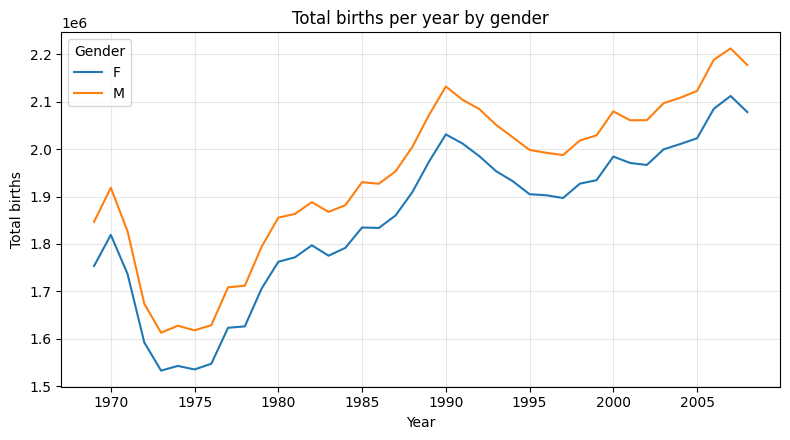

Average yearly gap (M - F): 92568
Average gap as percentage of female births: 5.02


In [4]:
yearly = births_raw.pivot_table(
    values="births",
    index="year",
    columns="gender",
    aggfunc="sum"
)

ax = yearly.plot(figsize=(8, 4.5))

ax.set_xlabel("Year")
ax.set_ylabel("Total births")
ax.set_title("Total births per year by gender")
ax.legend(title="Gender")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("fig_births_per_year.png", dpi=150, bbox_inches="tight")
plt.show()

print(
    "Average yearly gap (M - F):",
    round((yearly["M"] - yearly["F"]).mean())
)

print(
    "Average gap as percentage of female births:",
    round(((yearly["M"] / yearly["F"] - 1) * 100).mean(), 2)
)

In [5]:
# Calculate the first, second, and third quartiles
q1, q2, q3 = np.percentile(
    births["births"],
    [25, 50, 75
)

# Median as robust mean
u = q2

# Robust standard deviation
sig = 0.74 *(q3 - q1)

print("Q1 =", q1)
print("Median =", q2)
print("Q3 =", q3)
print("Robust mean (mu) =", mu)
print("Robust standard deviation (sigma) =" round(sig, 2))

print(
    "Accepted range:",
    round(mu - 5 * sig, 1),
    "to",
    round(mu + 5 * sig, 1)
)

Q1 = 4358.0
Median = 4814.0
Q3 = 5289.5
Robust mean (mu) = 4814.0
Robust standard deviation (sigma) = 689.31
Accepted range: 1367.5 to 8260.6


In [6]:
n_before = len(births)

# Keep records within five robust standard deviations
births = births.query(
    "(births > @mu - 5 * @sig) & "
    "(births < @mu + 5 * @sig)"
).copy()

print("Rows before cleaning:", n_before)
print("Rows after cleaning:", len(births))
print("Rows removed:", n_before - len(births))

Rows before cleaning: 15547
Rows after cleaning: 14610
Rows removed: 937


In [7]:
# Convert day after removing records with missing days
births["day"] = births["day"].astype(int)

print("\nData types after cleaning:")
print(births.dtypes)

print("\nMissing values remaining:")
print(births.isna().sum())


Data types after cleaning:
year      int64
month     int64
day       int64
gender      str
births    int64
dtype: object

Missing values remaining:
year      0
month     0
day       0
gender    0
births    0
dtype: int64


In [8]:
# Construct dates from year, month, and day
births.index = pd.to_datetime(
    births[["year", "month", "day"]]
)

# Add weekday and decade columns
births["dayofweek"] = births.index.dayofweek
births["decade"] = 10 * (births["year"] // 10)

print("Cleaned data with datetime index:")
print(births.head())

print(
    "\nDate range:",
    births.index.min().date(),
    "to",
    births.index.max().date()
)

Cleaned data with datetime index:
            year  month  day gender  births  dayofweek  decade
1969-01-01  1969      1    1      F    4046          2    1960
1969-01-01  1969      1    1      M    4440          2    1960
1969-01-02  1969      1    2      F    4454          3    1960
1969-01-02  1969      1    2      M    4548          3    1960
1969-01-03  1969      1    3      F    4548          4    1960

Date range: 1969-01-01 to 1988-12-31


Mean births by weekday and decade:
decade       1960    1970    1980
dayofweek                        
0          5063.8  4689.1  5276.9
1          5286.1  4885.3  5503.8
2          5074.6  4750.4  5367.6
3          4978.3  4696.9  5333.5
4          5107.9  4782.1  5393.1
5          4651.1  4207.8  4483.9
6          4342.3  3979.3  4308.1


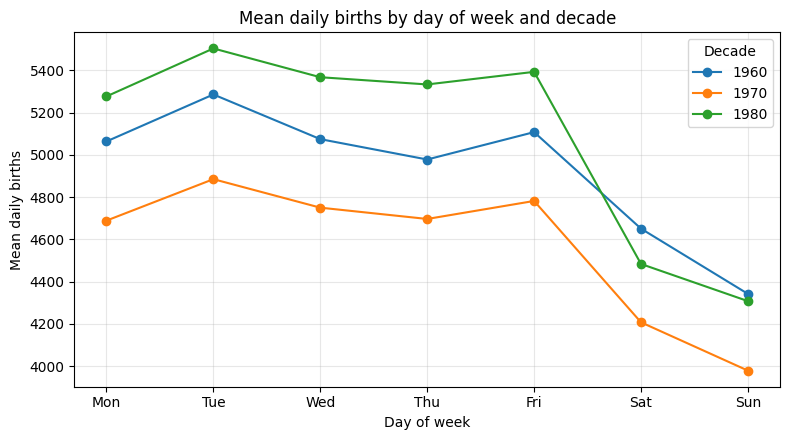

In [9]:
by_weekday = births.pivot_table(
    values="births",
    index="dayofweek",
    columns="decade",
    aggfunc="mean"
)

print("Mean births by weekday and decade:")
print(by_weekday.round(1))

# Plot weekday trends
ax = by_weekday.plot(
    figsize=(8, 4.5),
    marker="o"
)

ax.set_xticks(range(7))
ax.set_xticklabels(
    ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
)

ax.set_xlabel("Day of week")
ax.set_ylabel("Mean daily births")
ax.set_title("Mean daily births by day of week and decade")
ax.legend(title="Decade")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    "fig_births_by_weekday.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

In [10]:
print("Decades present after cleaning:")
print(sorted(births["decade"].unique()))

Decades present after cleaning:
[np.int64(1960), np.int64(1970), np.int64(1980)]


In [11]:
# Average births for each calendar date across years and genders
births_by_date = births.pivot_table(
    values="births",
    index=["month", "day"],
    aggfunc="mean"
)

print("Mean births by month and day:")
print(births_by_date.head())

# Convert the MultiIndex into columns
dates = births_by_date.index.to_frame(index=False)

# Attach a dummy leap year
dates["year"] = 2012

# Convert to a DatetimeIndex
births_by_date.index = pd.to_datetime(
    dates[["year", "month", "day"]]
)

print("\nMean births indexed by calendar date:")
print(births_by_date.head())

print("\nNumber of calendar dates:", len(births_by_date))

Mean births by month and day:
             births
month day          
1     1    4009.225
      2    4247.400
      3    4500.900
      4    4571.350
      5    4603.625

Mean births indexed by calendar date:
              births
2012-01-01  4009.225
2012-01-02  4247.400
2012-01-03  4500.900
2012-01-04  4571.350
2012-01-05  4603.625

Number of calendar dates: 366


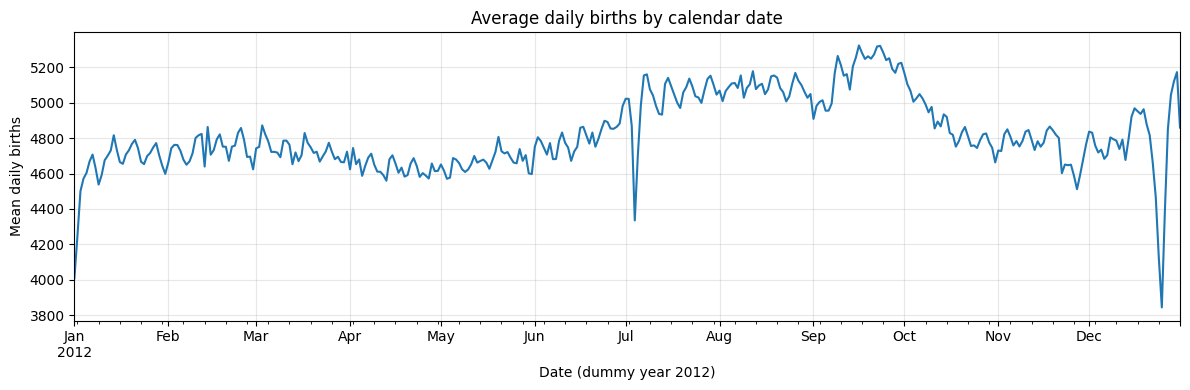

In [12]:
fig, ax = plt.subplots(figsize=(12, 4))

births_by_date.plot(
    ax=ax,
    legend=False
)

ax.set_xlabel("Date (dummy year 2012)")
ax.set_ylabel("Mean daily births")
ax.set_title("Average daily births by calendar date")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    "fig_births_by_date.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

In [13]:
# Find the ten calendar dates with the lowest mean births
lowest_dates = births_by_date["births"].nsmallest(10)

print("Ten calendar dates with the lowest mean births:")
print(lowest_dates.round(1))

Ten calendar dates with the lowest mean births:
2012-12-25    3844.4
2012-01-01    4009.2
2012-12-24    4126.2
2012-01-02    4247.4
2012-07-04    4335.3
2012-12-26    4383.5
2012-12-23    4466.7
2012-01-03    4500.9
2012-11-27    4511.6
2012-01-09    4537.8
Name: births, dtype: float64


In [14]:
# Group by decade and gender, then sum births
by_group = (
    births_raw.groupby(["decade", "gender"])["births"]
    .sum()
    .unstack()
)

print("Decade-by-gender table using groupby:")
print(by_group)

print(
    "\nIdentical to pivot table:",
    by_group.equals(decade_gender)
)

# Additional verification
pd.testing.assert_frame_equal(
    by_group,
    decade_gender
)

print("Verification successful.")

Decade-by-gender table using groupby:
gender         F         M
decade                    
1960     1753634   1846572
1970    16263075  17121550
1980    18310351  19243452
1990    19479454  20420553
2000    18229309  19106428

Identical to pivot table: True
Verification successful.


In [15]:
# Functions to benchmark
def run_pivot():
    return births_raw.pivot_table(
        values="births",
        index="decade",
        columns="gender",
        aggfunc="sum"
    )


def run_groupby():
    return (
        births_raw.groupby(["decade", "gender"])["births"]
        .sum()
        .unstack()
    )


# Warm up both methods
run_pivot()
run_groupby()

# Benchmark each method
repetitions = 100

start = time.perf_counter()

for _ in range(repetitions):
    run_pivot()

pivot_ms = (
    (time.perf_counter() - start)
    / repetitions
    * 1000
)

start = time.perf_counter()

for _ in range(repetitions):
    run_groupby()

groupby_ms = (
    (time.perf_counter() - start)
    / repetitions
    * 1000
)

# Display results in a table
timing = pd.DataFrame({
    "Method": ["pivot_table()", "groupby() + unstack()"],
    "Mean time (ms)": [pivot_ms, groupby_ms]
})

print("Execution time comparison:")
print(timing.round(4).to_string(index=False))

Execution time comparison:
               Method  Mean time (ms)
        pivot_table()          6.0267
groupby() + unstack()          2.0094


Five dates with the lowest mean births:
2012-12-25    3844.4
2012-01-01    4009.2
2012-12-24    4126.2
2012-01-02    4247.4
2012-07-04    4335.3
Name: births, dtype: float64


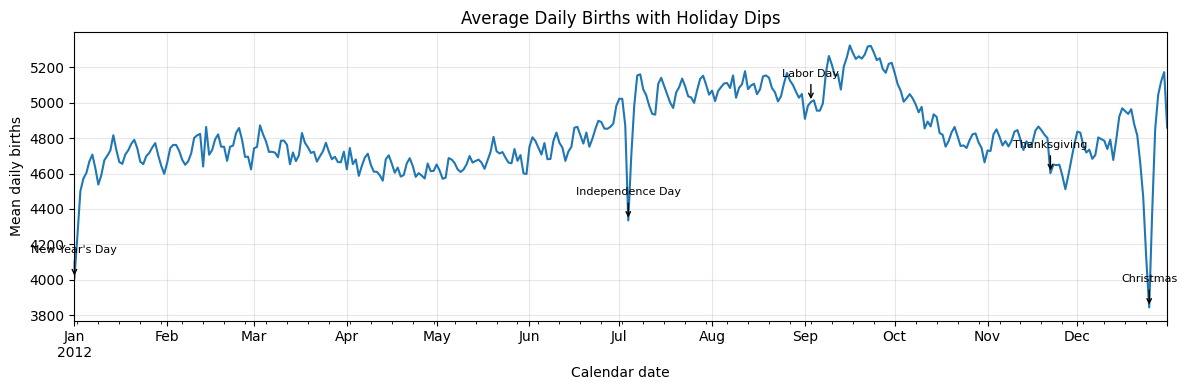

In [16]:
# Find the five dates with the lowest mean births
lowest_five = births_by_date["births"].nsmallest(5)

print("Five dates with the lowest mean births:")
print(lowest_five.round(1))

# Plot average births by calendar date
fig, ax = plt.subplots(figsize=(12, 4))

births_by_date.plot(ax=ax, legend=False)

ax.set_title("Average Daily Births with Holiday Dips")
ax.set_xlabel("Calendar date")
ax.set_ylabel("Mean daily births")
ax.grid(True, alpha=0.3)

# Holidays in dummy year 2012
holidays = {
    "New Year's Day": "2012-01-01",
    "Independence Day": "2012-07-04",
    "Labor Day": "2012-09-03",
    "Thanksgiving": "2012-11-22",
    "Christmas": "2012-12-25"
}

# Annotate holiday dates on the plot
for holiday, date in holidays.items():
    date = pd.Timestamp(date)

    if date in births_by_date.index:
        value = births_by_date.loc[date, "births"]

        ax.annotate(
            holiday,
            xy=(date, value),
            xytext=(0, 18),
            textcoords="offset points",
            ha="center",
            fontsize=8,
            arrowprops={"arrowstyle": "->"}
        )

plt.tight_layout()
plt.savefig(
    "fig_births_holiday_annotations.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()